In [1]:
# %load_ext autoreload
%reload_ext autoreload
%autoreload 2

In [2]:
#!/usr/bin/env python3

import gtsam
import gtsam_unstable
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
%matplotlib widget
import numpy as np
np.set_printoptions(linewidth=np.inf, suppress=True)
import copy
import time
from pathlib import Path
import open3d as o3d
from scipy.spatial import KDTree
from dataclasses import asdict
import yaml
import pickle

# Local imports
from common.customTypes import DecisionType
import common.FGVizHelpers as fgtools
from params.params import Params
from multiSession.SessionManager import SessionManager

from sparcification.NFR import GraphSparsification
from rosBagRead.readFromRosbags import ReadTopicsFromRosbag
from common.groundTruthLoader import GroundTruthLoader



Jupyter environment detected. Enabling Open3D WebVisualizer.
[Open3D INFO] WebRTC GUI backend enabled.
[Open3D INFO] WebRTCWindowSystem: HTTP handshake server disabled.


In [14]:
import matplotlib.pyplot as plt

# -------------------------------------------------------------------
# IEEE Conference Formatting Config
# -------------------------------------------------------------------
# Single-column width = 3.5 inches; Full-width = 7.16 inches
WIDTH_SINGLE = 3.5
WIDTH_DOUBLE = 7.16

# Aspect ratio helper (e.g., 4:3 ratio -> height = width * 0.75)
HEIGHT_SINGLE = WIDTH_SINGLE * 0.75 
# For 3 stacked panels, set height proportionally (e.g., 1.1x–1.3x column width)
HEIGHT_TRIPLE = WIDTH_SINGLE * 1.25

pgf_with_rc_fonts = {
    # Match paper typography (IEEE uses Times / Times New Roman)
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "DejaVu Serif"],
    
    # Enable LaTeX math rendering
    "text.usetex": False,  # Set to True if you have full TeX distribution installed
    "pdf.fonttype": 42,    # Embed TrueType fonts so text renders as scalable vectors
    "ps.fonttype": 42,

    # Font sizes relative to IEEE standard body text (10 pt) / figure captions (8 pt)
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "legend.fontsize": 8,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,

    # Line weights and spacing
    "lines.linewidth": 1.2,
    "lines.markersize": 4,
    "axes.linewidth": 0.8,
    "grid.linewidth": 0.5,
    "grid.alpha": 0.3,
    
    # Tight margins so axes labels aren't clipped
    "figure.autolayout": True,
}

plt.rcParams.update(pgf_with_rc_fonts)

# Timing Comparison Between Dense and Approximate Marginalization

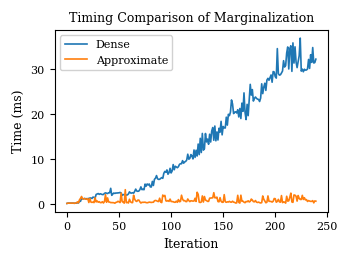

In [15]:
# Load timing pickle data and plot
timing_data_dense = np.loadtxt("../results/marginalizationEvaluation/nc/dense__quad-medium__quad-easy/DISTANCE/timeToOptimize.txt")
timing_data_approx = np.loadtxt("../results/marginalizationEvaluation/nc/approx__quad-medium__quad-easy/DISTANCE/timeToOptimize.txt")

# with open("../results/nc_tests/quad-medium_cov_current_pose_eval/update_timing_approx.pkl", "rb") as f:
#     timing_data_approx = pickle.load(f)

fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(WIDTH_SINGLE, HEIGHT_SINGLE))
ax.plot(timing_data_dense*1e3, label="Dense")
ax.plot(timing_data_approx*1e3, label="Approximate")
ax.set_xlabel("Iteration")
ax.set_ylabel("Time (ms)")
ax.set_title("Timing Comparison of Marginalization")
ax.legend(loc="upper left", frameon=True, framealpha=0.9)


# Comparison of Determinants of Covariance for Dense and Approximate Marginalizations

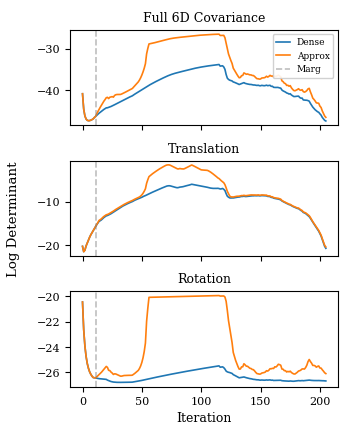

In [41]:
# Plot determinant of covariance matrices
plt.close("all")
with open("../results/marginalizationEvaluation/nc/dense__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_dense = np.asarray(pickle.load(f))

with open("../results/marginalizationEvaluation/nc/approx__quad-hard__quad-easy/cov_of_currentPoses.pkl", "rb") as f:
    cov_data_approx = np.asarray(pickle.load(f))

det_full_dense = np.linalg.det(cov_data_dense)
det_full_approx = np.linalg.det(cov_data_approx)

det_trans_dense = np.linalg.det(cov_data_dense[:, 3:, 3:])
det_trans_approx = np.linalg.det(cov_data_approx[:, 3:, 3:])

det_rot_dense = np.linalg.det(cov_data_dense[:, :3, :3])
det_rot_approx = np.linalg.det(cov_data_approx[:, :3, :3])

det_dense = np.log([det_full_dense, det_trans_dense, det_rot_dense])
det_approx = np.log([det_full_approx, det_trans_approx, det_rot_approx])

fig, ax = plt.subplots(3, 1, figsize=(WIDTH_SINGLE, HEIGHT_TRIPLE), sharex=True)
titles = ["Full 6D Covariance", "Translation", "Rotation"]

for i in range(3):
    # ax[i].set_yscale("log")
    ax[i].plot(det_dense[i], label="Dense")
    ax[i].plot(det_approx[i], label="Approx")
    ax[i].axvline(11, linestyle="--", color="tab:gray", alpha=0.5, label="Marg")
    ax[i].set_title(titles[i])
    if i == 2:
        ax[i].set_xlabel("Iteration")
    # ax[i].set_ylabel("Log Det")
    if i == 0:
        ax[i].legend(loc="upper right", frameon=True, framealpha=0.9, handlelength=1.5, fontsize=6.5)

fig.supylabel("Log Determinant")
# fig.supxlabel("Iterations")

# plt.suptitle("Determinant of Covariance Matrix of\n" + rf"Current Pose ($\mathcal{{V}}_l^t$)")
plt.tight_layout()
plt.show()

In [42]:
# MUST use bbox_inches="tight" when saving, otherwise the legend off-canvas gets cropped out
plt.savefig("icra_cov_eval_dense_vs_approx.pdf", format="pdf", dpi=300, bbox_inches="tight")

## Timing Plots For Each Decision Policy

In [25]:
DecisionType.NONE
dt.name == DecisionType.RELATIVE_COVARIANCE.name

True

Skipping None
DISTANCE: 204
OVERLAP: 204
INLIER_RATIO: 204
INLIER_RMSE: 204
TWO_STEP_VALIDATION: 204
RELATIVE_COVARIANCE: 204


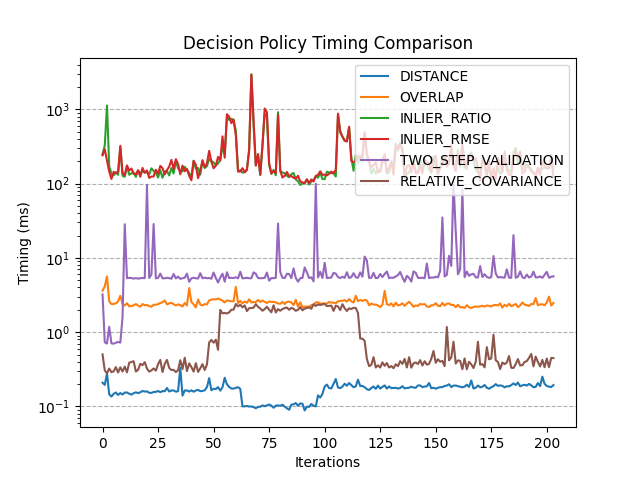

In [26]:
mainDir = Path("/home/benb/blocklio/python/results/nc/quad-hard_prior_quad-medium_prior_quad-easy")

timing_data: dict[str, np.ndarray] = {}
figName = "Timing Decision Policy"
plt.close(figName)
plt.figure(figName)
for dt in DecisionType:
    if dt.name == DecisionType.NONE.name:
        print("Skipping None")
        continue
    tmpPath = mainDir / dt.name / "timeToCalcMetricsAndDecision.txt"
    if not tmpPath.is_file():
        continue

    timing_data[dt.name] = np.loadtxt(tmpPath)
    print(f"{dt.name}: {timing_data[dt.name].size}")
    plt.plot(timing_data[dt.name] * 1e3, label=dt.name)

plt.yscale("log")
plt.xlabel("Iterations")
plt.ylabel("Timing (ms)")
plt.title("Decision Policy Timing Comparison")
plt.legend(loc="upper right")
plt.grid(axis='y', linestyle='--')


